# 06 · Interval optimization (systemic first)

Among stage III-IV patients who started systemic therapy first (or simultaneously), compares overall
survival by the gap before TACE: 0-3, 4-14 and 15-90 days (Figure 5), with pairwise IPTW comparisons.
Changing the bins to `[-1, 3, 21, 90]` gives the 4-21 / 22-90 day sensitivity grouping (Figure S4).

## Imports

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hcc_tace import config
from hcc_tace.plotting import DEFAULT, LARGE
from hcc_tace.survival import multigroup_logrank_p, survival_analysis, survival_analysis_3g
from hcc_tace.weighting import perform_iptw

config.setup_notebook()
covariates = config.COVARIATES

# Shared settings for the pairwise interval comparisons
INTERVAL = dict(
    group_col='spacing_group',
    style=replace(DEFAULT, annot_offsets=(-0.09, 0.03)),
    p_format='.4f',
    print_landmarks=False,
)

## Load Data

In [2]:
df_3g = pd.read_csv(config.ANALYSIS_READY)

## 3 group spacing analysis

### Analysis

In [3]:
#Advanced stage
df_3g = df_3g[df_3g['COMBINED_STAGE_GROUP'].isin([3,4])]
print(df_3g.shape)

#keep only systemic first or same day
print((df_3g['DX_IMMUNO_STARTED_DAYS'] > df_3g['DX_CHEMO_STARTED_DAYS']).sum())
df_3g = df_3g[df_3g['DX_IMMUNO_STARTED_DAYS'] <= df_3g['DX_CHEMO_STARTED_DAYS']]

#Define and filter treatment spacing
df_3g['treatment_spacing'] = abs(df_3g['DX_CHEMO_STARTED_DAYS'] - df_3g['DX_IMMUNO_STARTED_DAYS'])

(1426, 357)
945


In [4]:
print("percent of patients receiving TACE within 7 days:", (df_3g['treatment_spacing'] <= 7).sum()/df_3g.shape[0])
print("percent of patients receiving TACE within 30 days:", (df_3g['treatment_spacing'] <= 30).sum()/df_3g.shape[0])
print("percent of patients receiving TACE within 90 days:", (df_3g['treatment_spacing'] <= 90).sum()/df_3g.shape[0])
print("percent of patients receiving TACE within 90-365 days:", ((df_3g['treatment_spacing'] > 90) & (df_3g['treatment_spacing'] <= 365)).sum()/df_3g.shape[0])

percent of patients receiving TACE within 7 days: 0.5945945945945946
percent of patients receiving TACE within 30 days: 0.6985446985446986
percent of patients receiving TACE within 90 days: 0.8648648648648649
percent of patients receiving TACE within 90-365 days: 0.12681912681912683


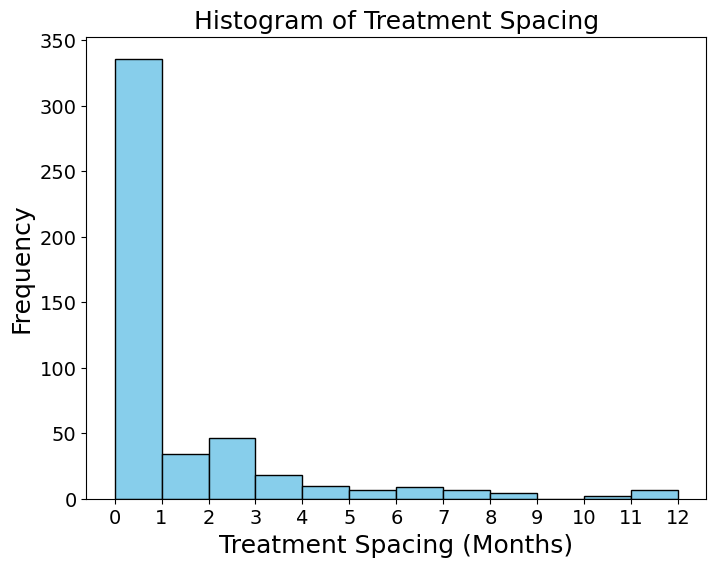

In [5]:
# Plot a histogram of treatment_spacing_months
df_3g['treatment_spacing_months'] = df_3g['treatment_spacing'] // 30
plt.figure(figsize=(8, 6))
df_3g['treatment_spacing_months'].hist(bins=np.arange(0, 13), color='skyblue', edgecolor='black')
plt.title('Histogram of Treatment Spacing', fontsize=18)
plt.xlabel('Treatment Spacing (Months)', fontsize=18)
plt.ylabel('Frequency', fontsize=18)
plt.xticks(np.arange(0, 13), fontsize=14)
plt.yticks(fontsize=14)
plt.grid(False)  # Remove the grid
plt.rcParams['pdf.fonttype'] = 42
#plt.savefig("treatment_spacing_histogram.pdf", format = 'pdf', bbox_inches='tight')
plt.show()

In [6]:
print((df_3g['treatment_spacing'] > 90).sum())
df_3g = df_3g[df_3g['treatment_spacing'] <= 90]
#Define spacing groups
df_3g['spacing_group'] = pd.cut(
    df_3g['treatment_spacing'], 
    bins=[-1, 3, 14, 90], 
    labels=[0, 1, 2], 
    right=True
)

df_3g['spacing_group'].value_counts()
print(df_3g['spacing_group'].dtype)

65
category


<lifelines.CoxPHFitter: fitted with 416 total observations, 115 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 416
number of events observed = 301
   partial log-likelihood = -1595.43
         time fit was run = 2026-11-01 22:29:13 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
spacing_0  0.50      1.65      0.28           -0.04            1.05                0.96                2.84
spacing_2  0.46      1.58      0.29           -0.11            1.02                0.90                2.79

           cmp to    z    p  -log2(p)
covariate                            
spacing_0    0.00 1.81 0.07      3.83
spacing_2    0.00 1.58 0.11      3.14
---
Concordance = 0.52
Partial AIC = 3194.86
log-likelihood ratio test = 3.80 on 2 df
-log2(p) of ll-ratio test = 2.74

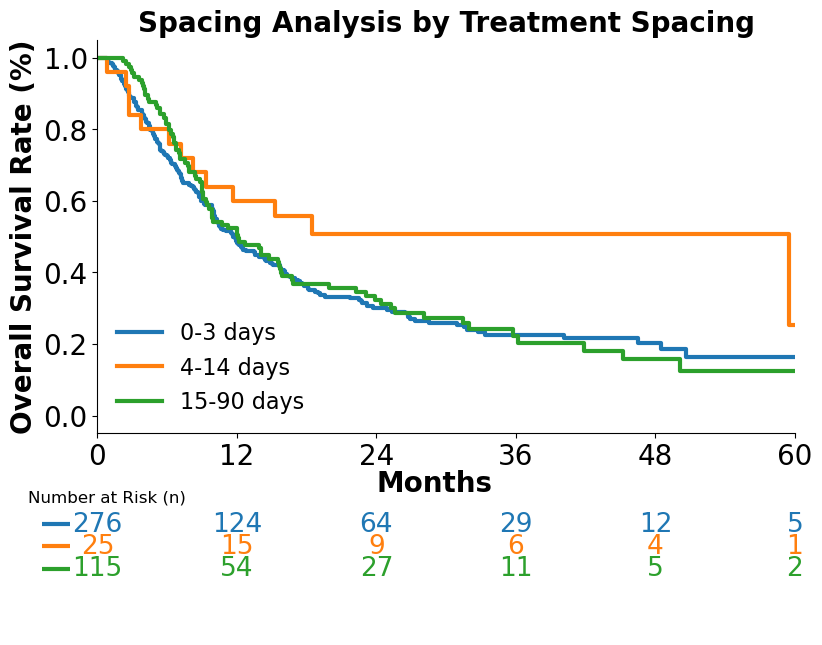

Logrank test p-value: 0.1868


In [7]:
df_3g['spacing_group'] = pd.Categorical(
    df_3g['spacing_group'],
    categories=[1, 0, 2],  # Set 4-14 days (1) as the reference group
    ordered=True
)

survival_analysis_3g(
    df_3g,
    np.arange(0, 61, 12),
    group_col='spacing_group',
    labels=['0-3 days', '4-14 days', '15-90 days'],
    title='Spacing Analysis by Treatment Spacing',
    dummy_prefix='spacing',
    style=LARGE,
    print_landmarks=False,
    # file_name='spacing_analysis_3g'
)

print(f"Logrank test p-value: {multigroup_logrank_p(df_3g, 'spacing_group'):.4f}")

## Pairwise

### Simultaneous vs 4-14 days

<lifelines.CoxPHFitter: fitted with 301 total observations, 84 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 301
number of events observed = 217
   partial log-likelihood = -1079.58
         time fit was run = 2026-11-01 22:29:13 UTC

---
               coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                      
spacing_group -0.49      0.61      0.28           -1.03            0.05                0.36                1.05

               cmp to     z    p  -log2(p)
covariate                                 
spacing_group    0.00 -1.77 0.08      3.70
---
Concordance = 0.51
Partial AIC = 2161.16
log-likelihood ratio test = 3.61 on 1 df
-log2(p) of ll-ratio test = 4.12

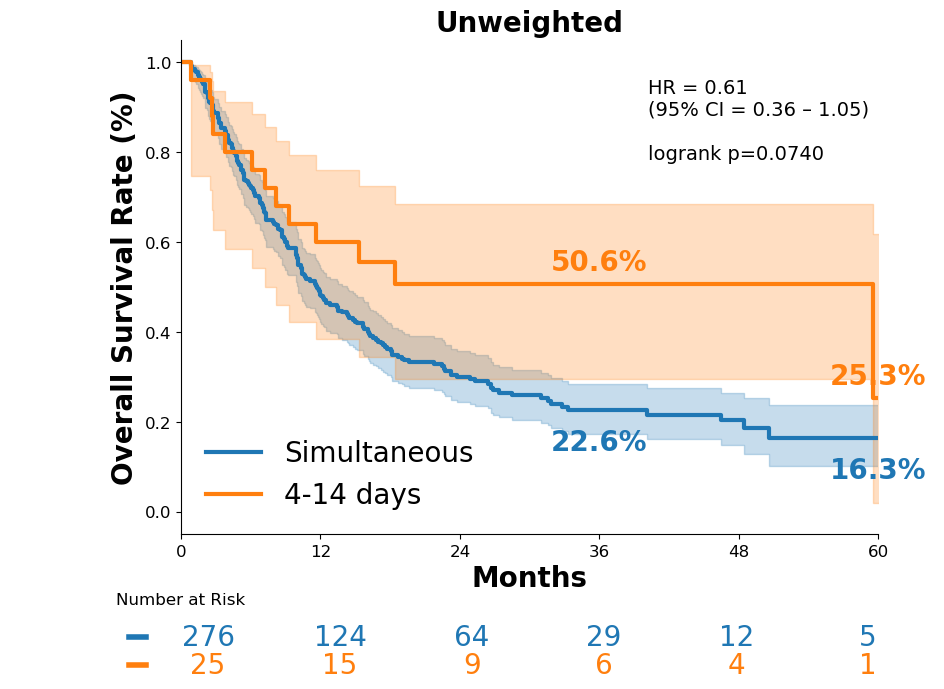

<lifelines.CoxPHFitter: fitted with 563.599 total observations, 190.715 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 563.599
number of events observed = 372.884
   partial log-likelihood = -2086.45
         time fit was run = 2026-11-01 22:29:14 UTC

---
               coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                      
spacing_group -0.50      0.61      0.11           -0.71           -0.29                0.49                0.75

               cmp to     z      p  -log2(p)
covariate                                   
spacing_group    0.00 -4.64 <0.005     18.13
---
Concordance = 0.51
Partial AIC = 4174.89
log-likelihood ratio test = 21.96 on 1 df
-log2(p) of ll-ratio test = 18.46

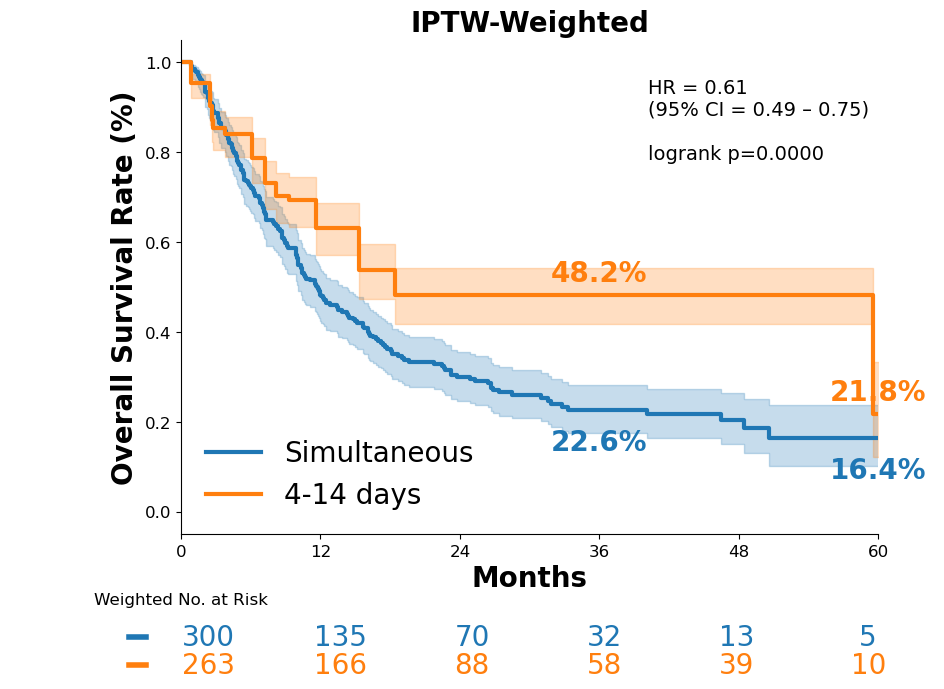

In [8]:
df_same_14 = df_3g[df_3g['spacing_group'].isin([0, 1])].copy()
df_same_14 = perform_iptw(df_same_14, covariates=covariates, treatment_col='spacing_group')

groups, colors = ['Simultaneous', '4-14 days'], ['#1f77b4', '#ff7f0e']
survival_analysis(df_same_14, np.arange(0, 61, 12), groups, colors, file_name='same_vs_14_days_unweighted', **INTERVAL)
survival_analysis(df_same_14, np.arange(0, 61, 12), groups, colors, weight_col='iptw_weight', file_name='same_vs_14_days_iptw', **INTERVAL);

### Simultaneous vs 15-90 days

<lifelines.CoxPHFitter: fitted with 391 total observations, 104 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 391
number of events observed = 287
   partial log-likelihood = -1503.99
         time fit was run = 2026-11-01 22:29:14 UTC

---
               coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                      
spacing_group  0.04      1.04      0.13           -0.21            0.30                0.81                1.35

               cmp to    z    p  -log2(p)
covariate                                
spacing_group    0.00 0.34 0.74      0.44
---
Concordance = 0.52
Partial AIC = 3009.97
log-likelihood ratio test = 0.11 on 1 df
-log2(p) of ll-ratio test = 0.44

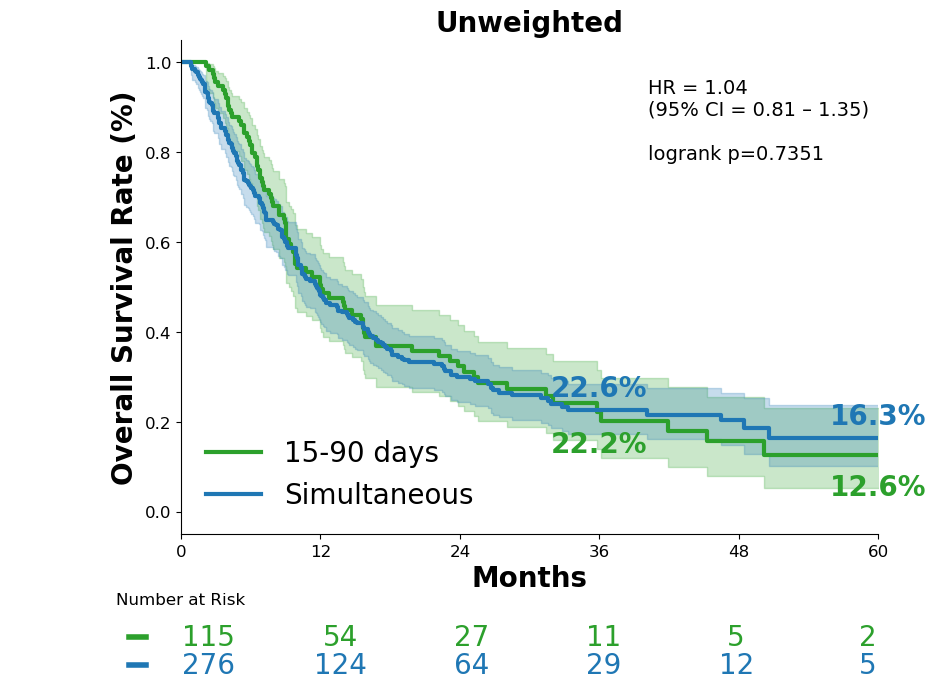

<lifelines.CoxPHFitter: fitted with 765.506 total observations, 202.686 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 765.506
number of events observed = 562.82
   partial log-likelihood = -3327.52
         time fit was run = 2026-11-01 22:29:14 UTC

---
               coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                      
spacing_group -0.03      0.97      0.08           -0.20            0.14                0.82                1.15

               cmp to     z    p  -log2(p)
covariate                                 
spacing_group    0.00 -0.35 0.72      0.47
---
Concordance = 0.48
Partial AIC = 6657.04
log-likelihood ratio test = 0.13 on 1 df
-log2(p) of ll-ratio test = 0.47

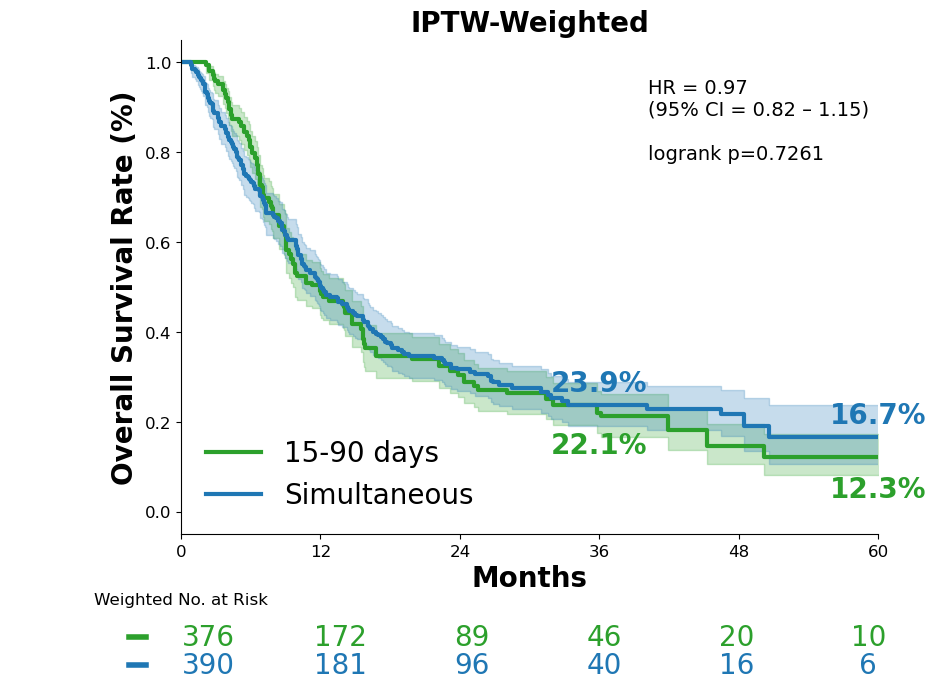

In [9]:
df_same_90 = df_3g[df_3g['spacing_group'].isin([0, 2])].copy()
df_same_90['spacing_group'] = (
    df_same_90['spacing_group']
    .cat.remove_unused_categories()
    .cat.rename_categories({0: 1, 2: 0})
)  # Relabel 15-90 days group to 0 and Simultaneous group to 1

df_same_90 = perform_iptw(df_same_90, covariates=covariates, treatment_col='spacing_group')

groups, colors = ['15-90 days', 'Simultaneous'], ['#2ca02c', '#1f77b4']
survival_analysis(df_same_90, np.arange(0, 61, 12), groups, colors, file_name='same_vs_90_days_unweighted', **INTERVAL)
survival_analysis(df_same_90, np.arange(0, 61, 12), groups, colors, weight_col='iptw_weight', file_name='same_vs_90_days_iptw', **INTERVAL);

### 4-14 days vs 15-90 days

<lifelines.CoxPHFitter: fitted with 140 total observations, 42 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 140
number of events observed = 98
   partial log-likelihood = -415.00
         time fit was run = 2026-11-01 22:29:14 UTC

---
               coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                      
spacing_group -0.48      0.62      0.29           -1.05            0.09                0.35                1.10

               cmp to     z    p  -log2(p)
covariate                                 
spacing_group    0.00 -1.64 0.10      3.32
---
Concordance = 0.52
Partial AIC = 832.00
log-likelihood ratio test = 3.02 on 1 df
-log2(p) of ll-ratio test = 3.60

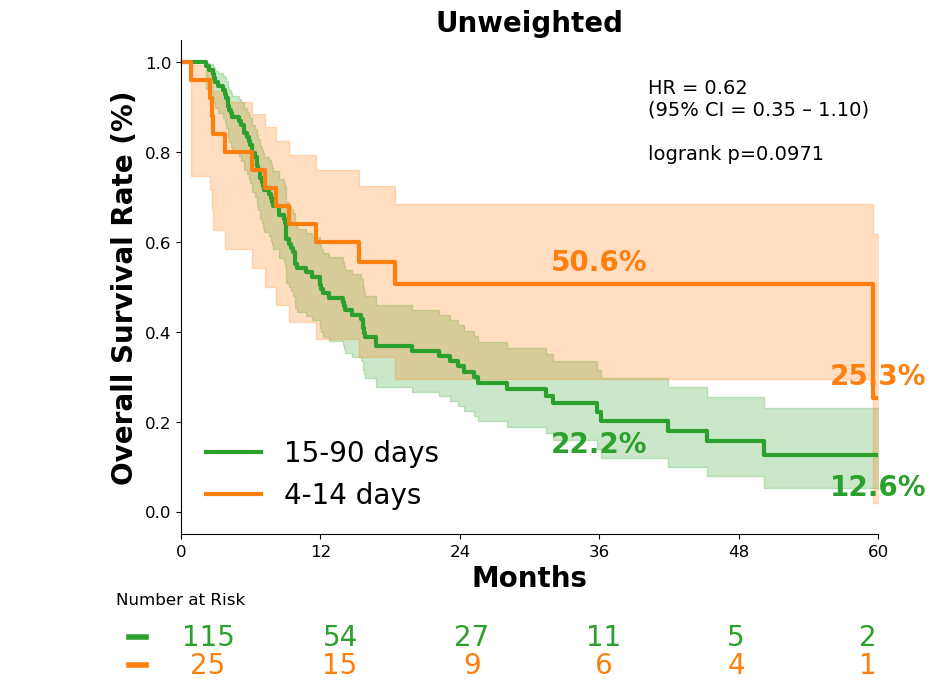

<lifelines.CoxPHFitter: fitted with 260.926 total observations, 100.806 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 260.926
number of events observed = 160.12
   partial log-likelihood = -782.36
         time fit was run = 2026-11-01 22:29:15 UTC

---
               coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                      
spacing_group -0.58      0.56      0.16           -0.90           -0.26                0.41                0.77

               cmp to     z      p  -log2(p)
covariate                                   
spacing_group    0.00 -3.52 <0.005     11.20
---
Concordance = 0.52
Partial AIC = 1566.73
log-likelihood ratio test = 12.90 on 1 df
-log2(p) of ll-ratio test = 11.57

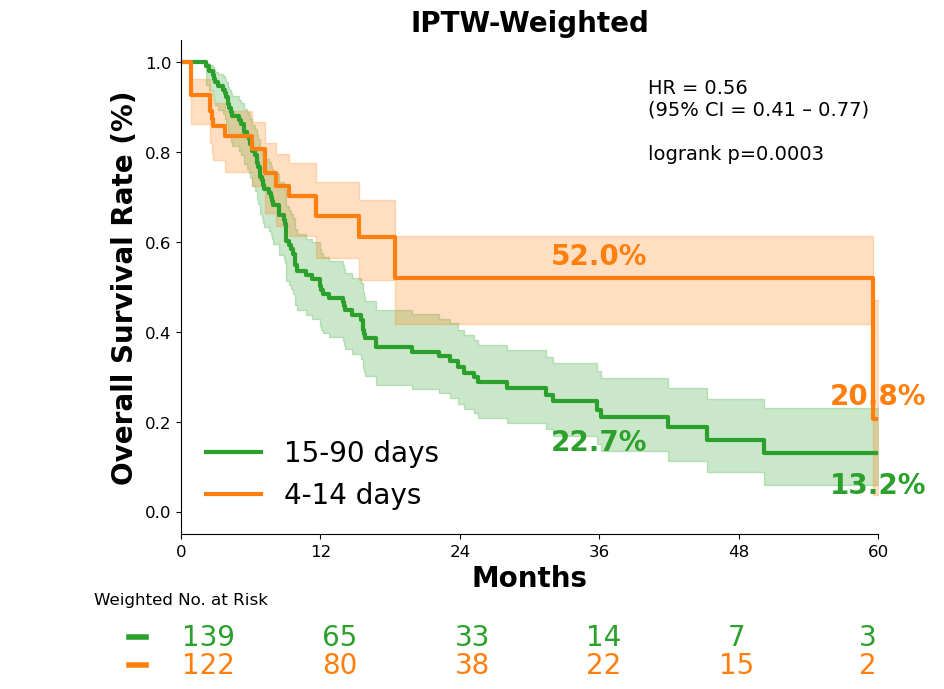

In [10]:
df_14_90 = df_3g[df_3g['spacing_group'].isin([1, 2])].copy()
df_14_90['spacing_group'] = (
    df_14_90['spacing_group']
    .cat.remove_unused_categories()
    .cat.rename_categories({2: 0})
)  # Relabel 15-90 days group to 0

df_14_90 = perform_iptw(df_14_90, covariates=covariates, treatment_col='spacing_group')

groups, colors = ['15-90 days', '4-14 days'], ['#2ca02c', '#ff7f0e']
survival_analysis(df_14_90, np.arange(0, 61, 12), groups, colors, file_name='14_vs_90_days_unweighted', **INTERVAL)
survival_analysis(df_14_90, np.arange(0, 61, 12), groups, colors, weight_col='iptw_weight', file_name='14_vs_90_days_iptw', **INTERVAL);